# Joint Maximal $p$-PIS (Probabilistic Invariant Set) and Model Learning
### Largest Invariant Set Inside Constraints $\mathcal{X}$, Compatible with Data

Manas Mejari, IDSIA, Lugano.

**Problem:** Given data $\{X^{+}, X\}$ generated from $x^{+} = A^{\star}x +w$ with $w \sim \mathcal{N}(0, Q)$; 
compute: a model $A$ and largest $\alpha>0$ such that the set $\mathcal{P}:= \{x:x^{\top}Px \leq \alpha\}$ is $p$-PIS.
Also, compute largest probability level $\tilde{p} \leq p$ for which $\mathcal{P}$ is $\tilde{p}$-PIs for the true system.

**Method:**
$$A_{\text{reg}} = \arg \min_{A\in\Theta_\delta}\;\frac{1}{N}\|X^{+}-AX\|_F^2 - \lambda \alpha^*(A)\quad\text{s.t.}\quad\rho(A)\leq\rho_{\max}=1-\beta\sqrt{c_p/\alpha_{\max}}$$
with $\alpha^*(A)=\beta^2 c_p/(1-\rho(A))^2$, $c_p=F^{-1}_{\chi^2_n}(p)$ (the code variable `cp` is $\sqrt{c_p}$), and $\Theta_\delta=\{A:\mathrm{tr}(Q^{-1}(A-\hat A)\Sigma_X(A-\hat A)^\top)\leq F^{-1}_{\chi^2_{n^2}}(1-\delta)\}$ (code $\delta$ = miscoverage). In the implementation, $\lambda\alpha^*(A)$ is replaced by the monotone proxy $\lambda\rho(A)$.

**Certified set:** $\mathcal{P}_{\alpha^*(A_{\text{reg}})}$ is a $\tilde{p}$-PIS for $A^\star$ with posterior probability $\geq 1-\delta$, with $\alpha^*(A_{\text{reg}})\leq\alpha_{\max}$ (fits inside $\mathcal{X}$).  
**Compared against:** LS/MLE baseline $\hat{A}$ with no invariance objective.

## 0. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from scipy.stats    import chi2
from scipy.linalg   import sqrtm
from scipy.optimize import minimize
import pandas as pd
import warnings; warnings.filterwarnings('ignore')

from pis_model_functions import *
from empirical_probability import empirical_pis

np.random.seed(42)
plt.rcParams.update({
    'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'figure.dpi': 110, 'lines.linewidth': 2,
    'axes.spines.top': False, 'axes.spines.right': False,
})
print('Ready.')

Ready.


## 1. System Setup

In [2]:
n      = 2
A_true = np.array([[ 0.4,  0.4],
                   [ 0.0,  0.4]])
Q = 0.1 * np.eye(n)
P = np.array([[0.98, 0.15],
              [0.15, 0.78]])

p     = 0.98    # target invariance probability
delta = 0.02    # code delta = miscoverage: 1-delta = 0.98 = paper's delta (credible level of Theta_delta)
lam   = 10     # lambda weights rho(A): 0=pure LS, large=max set size 
N     = 1000     # dataset size

# State constraint: box |x_i| <= x_bar
x_bar = np.array([5.0, 5.0])
H = np.vstack([ np.eye(n), -np.eye(n)])
h = np.concatenate([x_bar, x_bar])

alpha_max = alpha_max_polytopic(P, H, h)
rmax      = rho_max_from_alpha(alpha_max, P, Q, p)

print(f'A_true:\n{A_true}')
print(f'\nrho(A_true) = {rho(A_true,P):.4f}  (P-stable: {rho(A_true,P)<1})')
print(f'beta         = {beta_val(P,Q):.4f}')
print(f'alpha*(A*)   = {alpha_star(A_true,P,Q,p):.4f}  [oracle]')
print(f'\nState constraint: box |x_i| <= {x_bar}')
print(f'alpha_max  = {alpha_max:.4f}  [ceiling from X_c]')
print(f'rho_max    = {rmax:.4f}  [contraction constraint for p-PIS in X_c]')
print(f'Feasible (rho_max > 0): {rmax > 0}')

A_true:
[[0.4 0.4]
 [0.  0.4]]

rho(A_true) = 0.6877  (P-stable: True)
beta         = 0.3256
alpha*(A*)   = 8.5083  [oracle]

State constraint: box |x_i| <= [5. 5.]
alpha_max  = 18.9260  [ceiling from X_c]
rho_max    = 0.7906  [contraction constraint for p-PIS in X_c]
Feasible (rho_max > 0): True


## 3. Generate Data and MLE

In [3]:
X, Xp     = generate_data(A_true, Q, N)
A_hat, Sx = compute_mle(X, Xp) # Centre of the feasible ellipse
n2        = n**2
c_d2      = chi2.ppf(1 - delta, df=n2)

rho_hat  = rho(A_hat, P)
drho     = compute_delta_rho(P, Q, Sx, delta, n2)
rs, _    = rho_star(A_hat, P, Q, Sx, delta, n2)  

# Pre-compute LS quantities (used in all figures)
A_ls, ok = solve_joint_maximal(A_hat, X, Xp, Sx, P, Q, p, delta, alpha_max, 0)  # for lam =0 ==> pure LS objective,  no invariance objective

if A_ls is None or not ok:
    print('WARNING: optimisation failed, falling back to A_hat: no invariance objective')
    A_ls = A_hat.copy()

a_oracle = alpha_star(A_true, P, Q, p)
a_ls     = alpha_star(A_ls, P, Q, p)
rho_ls   = rho(A_ls, P)


pt_ls    = compute_ptilde(A_hat, A_ls, P, Q, Sx, delta, p) # Lower bound True probability level for LS solution
pstar_ls = compute_pstar(A_true, A_ls, P, p)

print(f'N = {N}')
print(f'A_hat (MLE):\n{np.round(A_hat,4)}')
print(f'A_ls (lam =0, invariance constraints):\n{np.round(A_ls,4)}')
print(f'||A_hat - A_true||_F = {np.linalg.norm(A_hat-A_true,"fro"):.4f}')
print(f'||A_ls - A_true||_F = {np.linalg.norm(A_ls-A_true,"fro"):.4f}')

print(f'\nTheta_delta: T(A_true)={theta_stat(A_true,A_hat,Q,Sx):.4f} <= {c_d2:.4f}: '
      f'{theta_stat(A_true,A_hat,Q,Sx)<=c_d2}')  # A_true belongs to the credible ellipsoid $\Theta_\delta$

print(f'\nTheta_delta: T(A_ls)={theta_stat(A_ls,A_hat,Q,Sx):.4f} <= {c_d2:.4f}: '
      f'{theta_stat(A_ls,A_hat,Q,Sx)<=c_d2}')  # A_ls belongs to the credible ellipsoid $\Theta_\delta$

print(f'\n rho_hat = {rho_hat:.4f},  delta_rho = {drho:.4f},  rho* = {rs:.4f}')

print(f'\n Feasibility in  alpha max: a_ls < alpha_max -> {a_ls:.4f} < {alpha_max:.4f} = {a_ls<alpha_max}')       # LS solution, constraint check in \alpha
print(f'Feasibility in  rho max: rho_ls < rho_max -> {rho_ls:.4f} < {rmax:.4f} = {rho_ls<rmax}')       # LS solution, constraint check in rho
print(f'Feasibility in rho max: rho* < rho_max -> {rs:.4f} < {rmax:.4f} = {rs<rmax}')       # bound rho_hat+delta_rho on max rho over Theta_delta vs rho_max
print(f'\nLS baseline: alpha*(A_ls)={a_ls:.4f},  p_tilde={pt_ls:.4f}, p_star={pstar_ls:.4f}')

N = 1000
A_hat (MLE):
[[ 0.4155  0.4107]
 [-0.018   0.4103]]
A_ls (lam =0, invariance constraints):
[[ 0.4155  0.4107]
 [-0.018   0.4103]]
||A_hat - A_true||_F = 0.0280
||A_ls - A_true||_F = 0.0280

Theta_delta: T(A_true)=2.5210 <= 11.6678: True

Theta_delta: T(A_ls)=0.0000 <= 11.6678: True

 rho_hat = 0.7038,  delta_rho = 0.0740,  rho* = 0.7779

 Feasibility in  alpha max: a_ls < alpha_max -> 9.4573 < 18.9260 = True
Feasibility in  rho max: rho_ls < rho_max -> 0.7038 < 0.7906 = True
Feasibility in rho max: rho* < rho_max -> 0.7779 < 0.7906 = True

LS baseline: alpha*(A_ls)=9.4573,  p_tilde=0.8893, p_star=0.9871


## 3. Solve Joint Maximal PIS, for LS set lam=0

In [4]:
A_reg, ok = solve_joint_maximal(A_hat, X, Xp, Sx, P, Q, p, delta, alpha_max, lam)
if A_reg is None or not ok:
    print('WARNING: optimisation failed, falling back to A_hat')
    A_reg = A_hat.copy()

rho_reg = rho(A_reg, P)
a_reg   = alpha_star(A_reg, P, Q, p)
pt_reg  = compute_ptilde(A_hat, A_reg, P, Q, Sx, delta, p)
pstar_reg = compute_pstar(A_true, A_reg, P, p)

print(f'Optimisation: {"OK" if ok else "FAILED"}')
print(f'\n{"Quantity":<48} {"Max-PIS":>10}  {"LS/MLE":>10}')
print('─'*70)
print(f'{"||A - A_true||_F":<48}  {np.linalg.norm(A_reg-A_true,"fro"):>10.4f} {np.linalg.norm(A_ls-A_true,"fro"):>10.4f}')
print(f'{"rho(A)":<48} {rho_reg:>10.4f}  {rho_ls:>10.4f}')
print(f'{"rho_max (contraction ceiling)":<48} {rmax:>10.4f}  {rmax:>10.4f}')
print(f'{"rho* (upper bound on max rho over Theta_delta)":<48} {rs:>10.4f}  {rs:>10.4f}')
print('─'*70)
print(f'{"alpha*(A_true) [oracle]":<48} {a_oracle:>10.4f}  {a_oracle:>10.4f}')
print(f'{"alpha*(A)  [model-certified set size]":<48} {a_reg:>10.4f}  {a_ls:>10.4f}')
print(f'{"alpha_max  [ceiling from X_c]":<48} {alpha_max:>10.4f}  {alpha_max:>10.4f}')
print(f'{"alpha*(A) <= alpha_max [fits in X_c?]":<48} {str(a_reg<=alpha_max):>10}  {str(a_ls<=alpha_max):>10}')
print('─'*70)
print(f'{"p_tilde [plant level, w.p. 1-delta]":<48} {pt_reg:>10.4f}  {pt_ls:>10.4f}')
print(f'{"p_star [Assuming known Astar]":<48} {pstar_reg:>10.4f}  {pstar_ls:>10.4f}')
print(f'{"target p":<48} {p:>10.4f}')
print(f'{"p_tilde < p [conservative bound below p?]":<48} {str(pt_reg<p):>10}  {str(pt_ls<p):>10}')
print(f'{"p_star  < p [mismatch degrades level?]":<48} {str(pstar_reg<p):>10}  {str(pstar_ls<p):>10}')
print('─'*70)
print(f'{"Set size gain: a_reg / a_ls":<48} {a_reg/max(a_ls,1e-9):>10.4f}')
print(f'{"p_tilde gain: pt_reg / pt_ls":<48} {pt_reg/max(pt_ls,1e-9):>10.4f}')
print(f'\nConclusion: Max-PIS achieves a LARGER set AND higher p_tilde than LS.')
print(f'Both have p_tilde <= p by construction (rho_hat + delta_rho over-approximates max rho over Theta_delta); the true-plant level p_star may exceed p.')

Optimisation: OK

Quantity                                            Max-PIS      LS/MLE
──────────────────────────────────────────────────────────────────────
||A - A_true||_F                                      0.0715     0.0280
rho(A)                                               0.7590      0.7038
rho_max (contraction ceiling)                        0.7906      0.7906
rho* (upper bound on max rho over Theta_delta)       0.7779      0.7779
──────────────────────────────────────────────────────────────────────
alpha*(A_true) [oracle]                              8.5083      8.5083
alpha*(A)  [model-certified set size]               14.2822      9.4573
alpha_max  [ceiling from X_c]                       18.9260     18.9260
alpha*(A) <= alpha_max [fits in X_c?]                  True        True
──────────────────────────────────────────────────────────────────────
p_tilde [plant level, w.p. 1-delta]                  0.9640      0.8893
p_star [Assuming known Astar]                    

## 4. Figure 1 — State Space: Certified Sets Inside $\mathcal{X}_c$

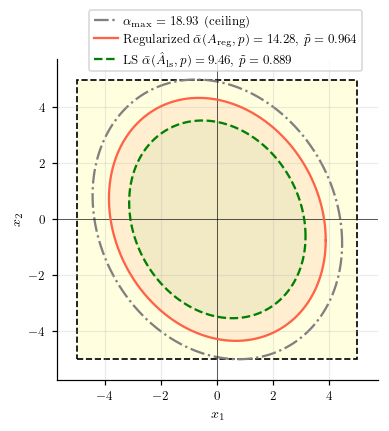

In [5]:
plt.rcParams.update({
    "font.size":       9,
    "axes.labelsize":  9,
    "axes.titlesize":  9,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "text.usetex": True,
    "font.family": "serif"
})

fig, ax = plt.subplots(figsize=(3.8, 3.8))


# State constraint box
box = MplPolygon(
    [[-x_bar[0],-x_bar[1]], [x_bar[0],-x_bar[1]],
     [x_bar[0], x_bar[1]], [-x_bar[0], x_bar[1]]],
    closed=True, fill=True, facecolor='lightyellow',
    edgecolor='black', linewidth=1.1, linestyle='--', zorder=0)
    #label='State constraint $\mathcal{X}$')
ax.add_patch(box)

# alpha_max boundary
xs, ys = ellipse_pts(P, alpha_max)
ax.plot(xs, ys, color='gray', lw=1.5, ls='-.', zorder=1,
        label=rf'$\alpha_{{\max}}={alpha_max:.2f}$ (ceiling)')

# Oracle
# xs, ys = ellipse_pts(P, a_oracle)
# ax.plot(xs, ys, color='orange', lw=1.5, ls=':', zorder=2,
#         label=rf'Oracle $\alpha^{{\star}}(A^{{\star}})={a_oracle:.2f}$')
# ax.fill(xs, ys, color='orange', alpha=0.07)

# Joint maximal PIS
xs, ys = ellipse_pts(P, a_reg)
ax.plot(xs, ys, color='tomato', lw=1.5, ls='-', zorder=4,
        label=rf'Regularized $\bar{{\alpha}}(A_{{\rm reg}},p)={a_reg:.2f}$,  $\tilde{{p}}={pt_reg:.3f}$')
ax.fill(xs, ys, color='tomato', alpha=0.10)

# LS baseline
if np.isfinite(a_ls):
    xs, ys = ellipse_pts(P, a_ls)
    ax.plot(xs, ys, color='green', lw=1.5, ls='--', zorder=3,
            label=rf'LS $\bar{{\alpha}}(\hat{{A}}_{{\rm ls}},p)={a_ls:.2f}$,  $\tilde{{p}}={pt_ls:.3f}$')
    ax.fill(xs, ys, color='green', alpha=0.05)




# Trajectory
#ax.scatter(X[0,:150], X[1,:150], s=5, color='steelblue', alpha=0.4, label='Training trajectory')

ax.set_xlabel('$x_1$');  ax.set_ylabel('$x_2$')
#ax.set_title(
#    f'Joint Maximal $p$-PIS  '
#    f'($p={p}$, $1-\\delta={1-delta}$, $N={N}$, $\\lambda={lam}$)')
ax.legend(loc='upper left', 
          bbox_to_anchor=(0.1, 1.15), 
          ncol=1,  
          borderaxespad=0.,
          frameon=True,
          columnspacing=1.2,
          handletextpad=0.4)

ax.set_aspect('equal');  ax.grid(True, alpha=0.25)
ax.axhline(0, color='k', lw=0.4);  ax.axvline(0, color='k', lw=0.4)
ax.set_xlim(-x_bar[0]*1.15, x_bar[0]*1.15)
ax.set_ylim(-x_bar[1]*1.15, x_bar[1]*1.15)
plt.tight_layout(pad=0.3)
plt.savefig('fig1_sets.pdf', bbox_inches='tight', pad_inches=0.02)
plt.show()

## 6. Effect of $\lambda$: Set Size vs. Data Fit

15 lambda values with a feasible solution out of 15


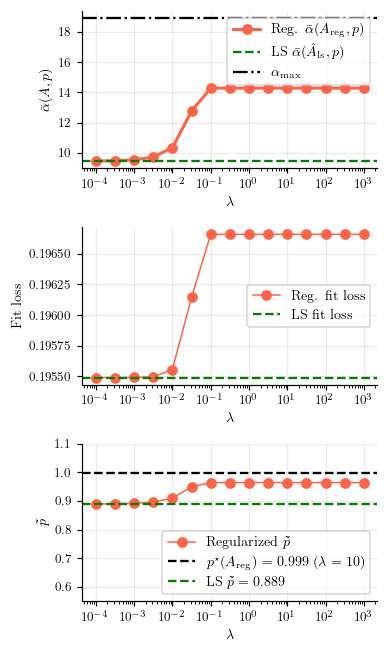

In [6]:
plt.rcParams.update({
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "text.usetex": True,
    "font.family": "serif"
})

lam_vals  = np.logspace(-4, 3, 15)
fit_ls_ref = np.linalg.norm(Xp - A_ls @ X, 'fro')**2
rows_lam  = []

for lam_i in lam_vals:
    Ari, ok_i = solve_joint_maximal(A_hat, X, Xp, Sx, P, Q, p, delta, alpha_max, lam_i)
    
    if Ari is None or not ok_i:
        continue
    fit_i = np.linalg.norm(Xp - Ari @ X, 'fro')**2
    rows_lam.append(dict(
        lam       = lam_i,
        fit       = fit_i,
        alpha_reg = alpha_star(Ari, P, Q, p),
        rho_reg   = rho(Ari, P),
        fit_ratio = fit_i / fit_ls_ref,
        ptilde    = compute_ptilde(A_hat, Ari, P, Q, Sx, delta, p),
        err       = np.linalg.norm(Ari - A_true, 'fro'),
    ))

dfl = pd.DataFrame(rows_lam)
print(f'{len(dfl)} lambda values with a feasible solution out of {len(lam_vals)}')

fig, axes = plt.subplots(3, 1, figsize=(3.6, 6))

# Left: set size vs lambda
ax  = axes[0]
ax.semilogx(dfl['lam'], dfl['alpha_reg'], 'o-', color='tomato', lw=2,
            label=rf'Reg. $\bar{{\alpha}}(A_{{\rm reg}},p)$')

#ax.axhline(a_oracle,  color='orange',  ls='--', lw=1.5, label=rf'Oracle $\alpha^{{\star}}(A^{{\star}})$')
ax.axhline(a_ls,      color='green', ls='--',  lw=1.5, label=rf'LS $\bar{{\alpha}}(\hat{{A}}_{{\rm ls}},p)$')
ax.axhline(alpha_max, color='black',   ls='-.', lw=1.5, label=rf'$\alpha_{{\max}}$')
ax.set_xlabel('$\lambda$')  
ax.set_ylabel(rf'$\bar{{\alpha}}(A,p)$')
#ax.set_title('Set size vs. $\\lambda$\n'
#             '($\\lambda\\to 0$: LS model , $\\lambda\\to\\infty$: max set)')
# ax.legend(loc='upper left', 
#           bbox_to_anchor=(0.0, 1.3), 
#           ncol=2,  
#           borderaxespad=0.,
#           frameon=True,
#           columnspacing=1.2,
#           handletextpad=0.4)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.25)

# Middle: fit vs lambda
ax  = axes[1]
ax.semilogx(dfl['lam'], dfl['fit']/N, 'o-', color='tomato', lw=1,
            label='Reg. fit loss')
ax.axhline(fit_ls_ref/N,      color='green', ls='--',  lw=1.5, label='LS fit loss')
ax.set_xlabel('$\lambda$')  
ax.set_ylabel('Fit loss')
#ax.set_title('Set size vs. $\\lambda$\n'
#             '($\\lambda\\to 0$: LS model , $\\lambda\\to\\infty$: max set)')
# ax.legend(loc='upper left', 
#           bbox_to_anchor=(0.0, 1.2), 
#           ncol=2,  
#           borderaxespad=0.,
#           frameon=True,
#           columnspacing=1.2,
#           handletextpad=0.4) 
ax.legend(fontsize=9)
ax.grid(True, alpha=0.25)



# right: p_tilde vs lambda
ax = axes[2]
ax.semilogx(dfl['lam'], dfl['ptilde'], 'o-', color='tomato', lw=1,
            label=rf'Regularized $\tilde{{p}}$')
ax.axhline(pstar_reg,     color='k',      ls='--', lw=1.5, label=rf'$p^{{\star}}(A_{{\rm reg}})={pstar_reg:.3f}$ ($\lambda={lam}$)')
ax.axhline(pt_ls, color='green', ls='--',  lw=1.5, label=f'LS $\\tilde{{p}}={pt_ls:.3f}$')
ax.set_xlabel('$\lambda$');  ax.set_ylabel(rf'$\tilde{{p}}$');  ax.set_ylim([0.55, 1.1])
#ax.set_title('Plant level $\\tilde{p}$ vs. $\\lambda$')
ax.legend(loc= 'lower right',fontsize=9);  
ax.grid(True, alpha=0.25)



plt.tight_layout()
plt.savefig('fig2_lambda.pdf', bbox_inches='tight')
plt.show()

## 7. Figure 3 — Effect of Dataset Size $N$

In [7]:
N_vals  = [100, 500, 1000, 2000, 4000, 10000]
rows_n  = []
lam = 10

for Ni in N_vals:
    Xi, Xpi   = generate_data(A_true, Q, Ni)
    Ahi, Sxi  = compute_mle(Xi, Xpi)
    Ari, ok_i = solve_joint_maximal(Ahi, Xi, Xpi, Sxi, P, Q, p, delta, alpha_max, lam)   # Regulaized solution
    Ali, ok_li = solve_joint_maximal(Ahi, Xi, Xpi, Sxi, P, Q, p, delta, alpha_max, 0)    # Non-regularized, LS solution
    dri       = compute_delta_rho(P, Q, Sxi, delta, n2)

    if Ari is None or not ok_i:
        rows_n.append(dict(N=Ni, alpha_reg=np.nan, alpha_ls=np.nan,
                           ptilde_reg=np.nan, ptilde_ls=np.nan,
                           drho=dri, err=np.nan))
        continue

    rows_n.append(dict(
        N          = Ni,
        lamN_ratio = lam/Ni,
        alpha_reg  = alpha_star(Ari, P, Q, p),
        alpha_ls   = alpha_star(Ali, P, Q, p),
        ptilde_reg = compute_ptilde(Ahi, Ari, P, Q, Sxi, delta, p),
        ptilde_ls  = compute_ptilde(Ahi, Ali, P, Q, Sxi, delta, p),
        drho       = dri,
        err        = np.linalg.norm(Ari - A_true, 'fro'),
        err_ls     = np.linalg.norm(Ali - A_true, 'fro'),
    ))

dfn = pd.DataFrame(rows_n)
print(dfn.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

    N  lamN_ratio  alpha_reg  alpha_ls  ptilde_reg  ptilde_ls   drho    err  err_ls
  100      0.1000    18.9260   10.7687      0.6908     0.4872 0.1629 0.1491  0.0598
  500      0.0200    14.4447    7.7250      0.9705     0.8479 0.1003 0.0972  0.0359
 1000      0.0100    10.8456    6.1741      0.9799     0.8919 0.0902 0.0460  0.0555
 2000      0.0050    11.7562    8.3051      0.9662     0.9086 0.0689 0.0635  0.0424
 4000      0.0025    10.1350    7.8743      0.9643     0.9248 0.0606 0.0344  0.0118
10000      0.0010     9.6893    8.0294      0.9748     0.9526 0.0376 0.0235  0.0152


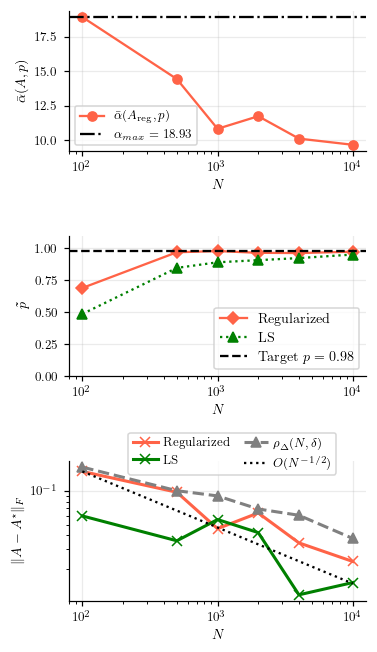

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(3.5, 6))
Nv = dfn['N'].values

# Left: set sizes
ax = axes[0]
ax.semilogx(Nv, dfn['alpha_reg'], 'o-',  color='tomato',  lw=1.5,
            label=rf'$\bar{{\alpha}}(A_{{\rm reg}},p)$')

#ax.axhline(a_oracle,  color='orange',  ls='--', lw=1.5, label=rf'Oracle $\alpha^{{\star}}(A^{{\star}})$')
#ax.axhline(a_ls,  color='green', ls=':', lw=2, label=rf'LS $\alpha^{{\star}}(\hat{A})$ ')
ax.axhline(alpha_max, color='black',  ls='-.', lw=1.5, label=f'$\\alpha_{{max}}={alpha_max:.2f}$')
ax.set_xlabel('$N$');  ax.set_ylabel('$\\bar{\\alpha}(A,p)$')
#ax.set_title('Certified set sizes vs. $N$\n'
#             'Max-PIS grows $\\nearrow$, LS shrinks $\\searrow$, both $\\to$ oracle')
ax.legend(fontsize=8);  ax.grid(True, alpha=0.25)

# Middle: p_tilde
ax = axes[1]
ax.semilogx(Nv, dfn['ptilde_reg'], 'D-', color='tomato',  lw=1.5,
            label='Regularized')
ax.semilogx(Nv, dfn['ptilde_ls'],  '^:', color='green',  lw=1.5,
            label='LS')
ax.axhline(p, color='k', ls='--', lw=1.5, label=f'Target $p={p}$')
ax.set_xlabel('$N$');  ax.set_ylabel('$\\tilde{p}$');  ax.set_ylim([0, 1.1])
#ax.set_title('Plant level $\\tilde{p}(N)$\n'
#             '$\\tilde{p} < p$ always; $\\tilde{p}\\nearrow p$ as $N\\to\\infty$')
ax.legend(fontsize=9);  ax.grid(True, alpha=0.25)

# Right: mismatch and error
ax = axes[2]
mask = dfn['err'].notna()
ax.semilogx(Nv[mask], dfn['err'][mask],  'x-', color='tomato', label='Regularized')
ax.semilogx(Nv[mask], dfn['err_ls'][mask],  'x-', color='green', label='LS')
ax.semilogx(Nv,       dfn['drho'],       '^--', color='gray',  label=rf'$\rho_{{\Delta}}(N,\delta)$')
ref = dfn['err'][mask].values[0] * np.sqrt(N_vals[0] / Nv[mask])
ax.loglog(Nv[mask], ref, 'k:', lw=1.5, label='$O(N^{-1/2})$')
ax.set_xlabel('$N$') 
ax.set_ylabel('$\\|A-A^\\star\\|_F$')  
#ax.set_title('Parameter error and mismatch bound')
ax.legend(loc='upper left', 
          bbox_to_anchor=(0.2, 1.2), 
          ncol=2,  
          borderaxespad=0.,
          frameon=True,
          columnspacing=1.2,
          handletextpad=0.4) 

ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.savefig('fig3_N.pdf', bbox_inches='tight')
plt.show()

In [9]:
##  5. Figure 2 — Monte Carlo Validation

In [10]:
N_init       = 5000
Nw           = 5000
T            = 20
plot_steps   = (1, 2, 10) 
vis_init_idx = 15

p_hat_k,  p_hat_cert, X_vis_t, X0 = empirical_pis(A_true, P, a_reg, Q,
                  N_init=N_init,
                  Nw=Nw,
                  T=T,
                  plot_steps=plot_steps,
                  vis_init_idx=vis_init_idx,
                  boundary_frac=1,
                  p_target = pt_reg,
                  pt_lb    = pstar_reg,
                  seed=42,
                  xlabel='$x_1$',
                  ylabel='$x_2$'
                  )

# ── Print results ─────────────────────────────────────────────────────
print(f"\n{'='*55}")
print(f"  Empirical p-PIS Validation")
print(f"  N_init={N_init},  Nw={Nw},  T={T}")
print(f"{'─'*55}")
print(f"  Empirical avg p_k    = {p_hat_k.mean():.4f}")
print(f"  Empirical min_{{k}} p_k  = {p_hat_cert:.5f}  <- worst-case empirical p_hat_emp (certified lower bound p_tilde = {pt_reg:.4f})")


  Empirical p-PIS Validation
  N_init=5000,  Nw=5000,  T=20
───────────────────────────────────────────────────────
  Empirical avg p_k    = 1.0000
  Empirical min_{k} p_k  = 0.99998  <- worst-case empirical p_hat_emp (certified lower bound p_tilde = 0.9640)


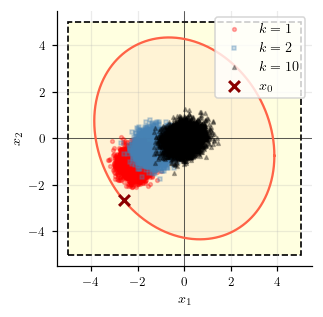

In [11]:
# ── Plot ──────────────────────────────────────────────────────────────
step_colors  = {s: c for s, c in zip(
        sorted(plot_steps), ['red', 'steelblue', 'black'])}
step_markers = {s: m for s, m in zip(
        sorted(plot_steps), ['o', 's', '^'])}

fig, axes = plt.subplots(1, 1, figsize=(3, 3))

# ── Left: state space scatter ─────────────────────────────────────────
ax = axes
# State constraint box
box = MplPolygon(
        [[-x_bar[0],-x_bar[1]], [x_bar[0],-x_bar[1]],
         [x_bar[0], x_bar[1]], [-x_bar[0], x_bar[1]]],
        closed=True, fill=True, facecolor='lightyellow',
        edgecolor='black', linewidth=1.1, linestyle='--', zorder=0)
    #label='State constraint $\mathcal{X}$')
ax.add_patch(box)

# Ellipse boundary
th  = np.linspace(0, 2*np.pi, 1000)
cir = np.stack([np.cos(th), np.sin(th)])
L_  = np.linalg.cholesky(a_reg * np.linalg.inv(P))
pts = L_ @ cir
ax.plot(pts[0], pts[1], color='tomato', lw=1.5, zorder=4)
ax.fill(pts[0], pts[1], color='tomato', alpha=0.07)

# Scatter at each plot step
for k_plot in sorted(plot_steps):
    if k_plot in X_vis_t:
        col = step_colors[k_plot]
        mk  = step_markers[k_plot]
        xp  = X_vis_t[k_plot]
        ax.scatter(xp[0], xp[1], s=6, color=col, alpha=0.3,
                       marker=mk, label=f'$k={k_plot}$',
                       zorder=3, rasterized=True)

# Initial condition (red cross)
x0v = X0[:, vis_init_idx]
ax.scatter(x0v[0], x0v[1], s=50, color='darkred',
           marker='x', linewidths=2,
           label='$x_0$', zorder=6)

ax.set_xlabel('$x_1$');  ax.set_ylabel('$x_2$')

ax.set_aspect('equal'); ax.grid(True, alpha=0.25)
ax.axhline(0, color='k', lw=0.4); ax.axvline(0, color='k', lw=0.4)
ax.legend(fontsize=9, loc='upper right')



plt.tight_layout()
plt.savefig('fig4_emp.pdf', bbox_inches='tight')
plt.show()

## 8. Figure 4 — Certified Sets for Increasing $N$

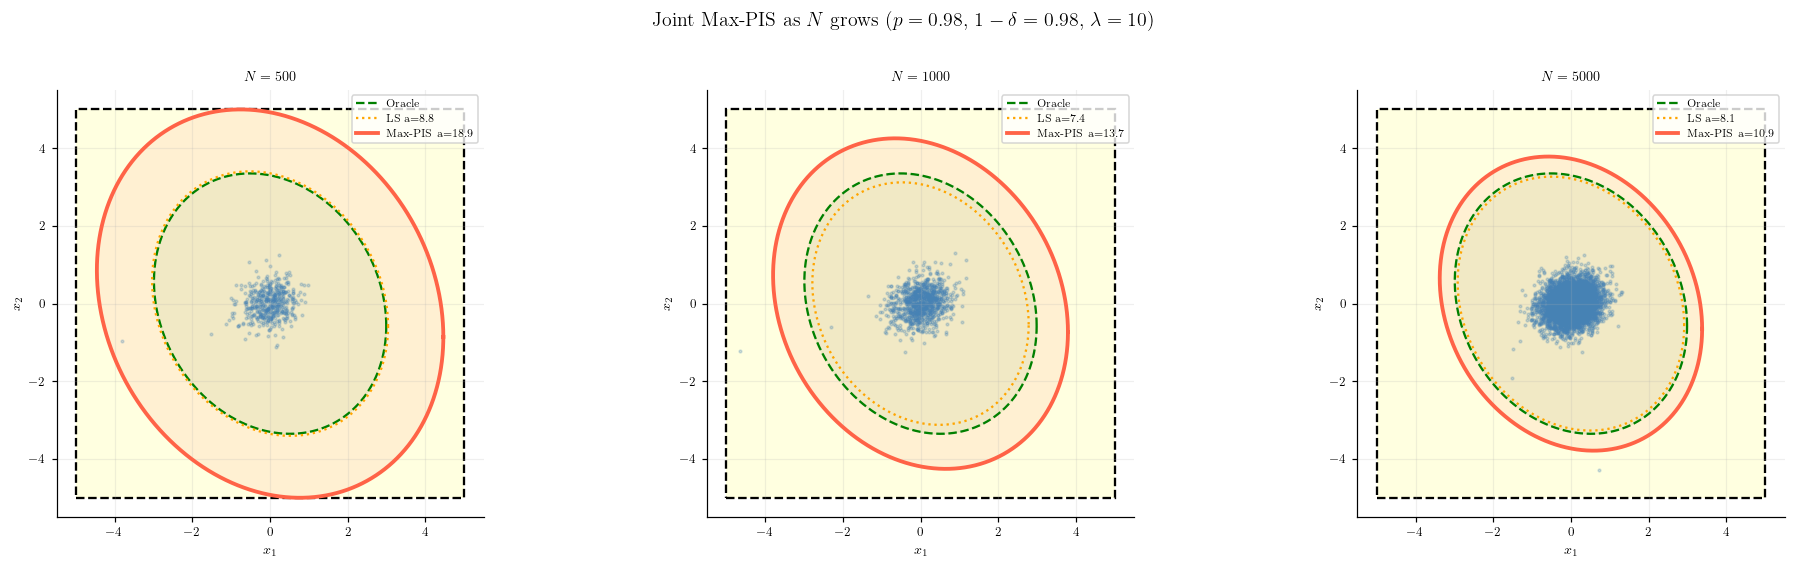

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
N_panel = [500, 1000,  5000]

for idx, Ni in enumerate(N_panel):
    ax = axes[idx]
    Xi, Xpi   = generate_data(A_true, Q, Ni)
    Ahi, Sxi  = compute_mle(Xi, Xpi)
    Ari, ok_i = solve_joint_maximal(Ahi, Xi, Xpi, Sxi, P, Q, p, delta, alpha_max, lam)
    a_ls_i  = alpha_star(Ahi, P, Q, p)

    # Box constraint
    box = MplPolygon(
        [[-x_bar[0],-x_bar[1]],[x_bar[0],-x_bar[1]],
         [x_bar[0], x_bar[1]],[-x_bar[0], x_bar[1]]],
        closed=True, fill=True, facecolor='lightyellow',
        edgecolor='black', linewidth=1.5, linestyle='--', zorder=0)
    ax.add_patch(box)

    # Oracle
    xs, ys = ellipse_pts(P, a_oracle)
    ax.plot(xs, ys, 'g--', lw=1.5, label='Oracle')
    ax.fill(xs, ys, color='green', alpha=0.06)

    # LS
    if np.isfinite(a_ls_i):
        xs, ys = ellipse_pts(P, a_ls_i)
        ax.plot(xs, ys, color='orange', lw=1.5, ls=':', label=f'LS a={a_ls_i:.1f}')

    # Max-PIS
    if Ari is not None and ok_i:
        a_reg_i = alpha_star(Ari, P, Q, p)
        if np.isfinite(a_reg_i):
            xs, ys = ellipse_pts(P, a_reg_i)
            ax.plot(xs, ys, color='tomato', lw=2.5, label=f'Max-PIS a={a_reg_i:.1f}')
            ax.fill(xs, ys, color='tomato', alpha=0.09)
    else:
        ax.text(0.1, 0.5, 'Infeasible\n(need more data)',
                transform=ax.transAxes, color='tomato', fontsize=9)

    ax.scatter(Xi[0,:], Xi[1,:], s=3, color='steelblue', alpha=0.25)
    ax.set_title(f'$N = {Ni}$')
    ax.set_xlabel('$x_1$');  ax.set_ylabel('$x_2$')
    ax.legend(fontsize=7, loc='upper right')
    ax.set_aspect('equal');  ax.grid(True, alpha=0.2)
    ax.set_xlim(-x_bar[0]*1.1, x_bar[0]*1.1)
    ax.set_ylim(-x_bar[1]*1.1, x_bar[1]*1.1)

plt.suptitle(
    f'Joint Max-PIS as $N$ grows  ($p={p}$, $1-\\delta={1-delta}$, $\\lambda={lam}$)',
    fontsize=13, y=1.02)
plt.tight_layout()
#plt.savefig('fig4_panel_N.pdf', bbox_inches='tight')
plt.show()

##  Summary

In [13]:
print('='*68)
print('  JOINT MAXIMAL p-PIS — SUMMARY')
print('='*68)
print(f'  System:  n={n},  N={N},  p={p},  1-delta={1-delta},  lambda={lam}')
print(f'  X_c:     box |x_i| <= {x_bar},  alpha_max = {alpha_max:.4f}')
print(f'  delta_rho = {drho:.4f}  (mismatch bound, O(N^(-1/2)))')
print('-'*68)
print(f'  {"":<42} {"Regularized":>10}  {"LS/MLE":>10}')
print('-'*68)
print(f'  {"rho(A)":<42} {rho_reg:>10.4f}  {rho_ls:>10.4f}')
print(f'  {"alpha*(A)  [model-certified set]":<42} {a_reg:>10.4f}  {a_ls:>10.4f}')
print(f'  {"p_tilde    [plant level w.p. 1-delta]":<42} {pt_reg:>10.4f}  {pt_ls:>10.4f}')
print(f'  {"prescribed p":<42} {p:>10.4f}  {p:>10.4f}')
print('-'*68)
print(f'  Oracle alpha*(A*) = {a_oracle:.4f}')
print(f'  Set size gain (Max-PIS / LS): x{a_reg/max(a_ls,1e-9):.3f}')
print(f'  p_tilde gain  (Max-PIS / LS): x{pt_reg/max(pt_ls,1e-9):.3f}')


  JOINT MAXIMAL p-PIS — SUMMARY
  System:  n=2,  N=1000,  p=0.98,  1-delta=0.98,  lambda=10
  X_c:     box |x_i| <= [5. 5.],  alpha_max = 18.9260
  delta_rho = 0.0740  (mismatch bound, O(N^(-1/2)))
--------------------------------------------------------------------
                                             Regularized      LS/MLE
--------------------------------------------------------------------
  rho(A)                                         0.7590      0.7038
  alpha*(A)  [model-certified set]              14.2822      9.4573
  p_tilde    [plant level w.p. 1-delta]          0.9640      0.8893
  prescribed p                                   0.9800      0.9800
--------------------------------------------------------------------
  Oracle alpha*(A*) = 8.5083
  Set size gain (Max-PIS / LS): x1.510
  p_tilde gain  (Max-PIS / LS): x1.084
